# 09 · ROOT files from Python: uproot and RDataFrame

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jhputschke/js-contrib/blob/main/tutorials/pyjetscape/09_root_from_python.ipynb)

**Time:** 40 minutes · **Needs:** any setup · **Data:** `auau_stats` and `pp_ref`: the ROOT files and the jet_frag HDF5 files (0.3 GB, downloaded once)

Most analyses in heavy-ion physics are written in ROOT. The production writes HDF5, so
`run_h5toROOT.py` copies the hadrons and the event record of every job into a ROOT file,
plus one campaign file with the cross sections. This tutorial reads those files from Python,
without ROOT, with [uproot](https://uproot.readthedocs.io) and
[awkward arrays](https://awkward-array.org). It:
- shows what the converter writes, and why one entry is one oversample;
- reads the event record, the p̂T windows, the campaign's cross sections and the provenance;
- handles the hadrons of every sample as jagged (awkward) arrays;
- makes a cross-section-weighted spectrum with `hist`, and checks it against the HDF5 reader;
- shows the same with RDataFrame, for readers who have PyROOT.

The data are 120 Au+Au events (0–10 %, 200 GeV) in three p̂T windows, and their p+p
reference (4,500 events in vacuum, the same windows). Tutorial 10 reads the same files in C++.

Reference pages: [ROOT and C++](https://jhputschke.github.io/js-contrib/analysis/root/),
[What a production writes](https://jhputschke.github.io/js-contrib/analysis/files/).

> **Work in progress: examples, not vetted physics.** The tutorials show how to run the
> simulation and use its outputs. The data sets are small, so the statistics are low, and
> the analyses have not been checked to the standard of a publication: treat every number
> and figure as an illustration, not as a physics result.

> **The outputs shown** were produced on an Apple Silicon Mac, in the environment the xscape wheel 0.2.0 is built in, with the hydro on the GPU through Metal.

In [1]:
# Setup: the tutorial helpers sit next to this notebook (_common/). In Colab they are
# fetched first, with the jetscape readers; locally nothing is installed.
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.isdir("_common"):
    subprocess.run("curl -sL https://codeload.github.com/jhputschke/js-contrib/tar.gz/refs/heads/main"
                   " | tar xz --strip-components=3 js-contrib-main/tutorials/pyjetscape",
                   shell=True, check=True)
sys.path.insert(0, os.getcwd())
from _common import tutorial_env as te
te.colab_install()
env = te.setup()

tutorials v2 | setup: source (runs X-SCAPE; hydro: Metal GPU) | Python 3.13.1 | data: data/


## 1. What `run_h5toROOT.py` writes, and why

A production job writes its hadrons into three HDF5 files, one per *tag*: `bulk_jet` (the
medium with the jet's wake, sampled from the jet leg's freeze-out surface), `bulk_bg` (the
medium alone, from the background's surface) and `jet_frag` (the jet's own hadrons).
`run_h5toROOT.py` turns each job into **one** ROOT file, `<stem>_hadrons.root`:

| object | one entry per | content |
|---|---|---|
| `bulk_jet`, `bulk_bg`, `jet_frag` | sample | `event`, `unit`, `sample`, `bg_unit`, and per hadron `pid`, `pstat`, `E`, `px`, `py`, `pz` (and `t`, `x`, `y`, `z` if the job kept positions) |
| `events` | event | the event record: p̂T window, background, parton and droplet summaries, the shower initiators `ini_*` |
| `windows` | p̂T window | this job's cross-section estimate of each window |
| `provenance` | – | a JSON string: every setting, seed and input behind the file |

It also writes one **campaign file** for all jobs together, with the combined cross sections.

**Why one entry per sample?** A sample (an *oversample* of the bulk, or one fragmentation of
the jet) is a complete set of hadrons, like one Monte Carlo event. One entry per event would
hold all samples of an event at once, millions of hadrons at a few hundred oversamples. One
entry per hadron would lose the event. So an entry reads like an event, and the columns
`event`, `unit` and `sample` say which event and which sample it is. Keep in mind that the
samples of one event share one fluid: they are not independent events.

The files are **RNTuples**, ROOT's new columnar format (ROOT ≥ 6.34 reads them;
`--format ttree` writes classic TTrees for older ROOT). The sizes of this set, per job:

In [2]:
import numpy as np
import pandas as pd

pd.set_option("display.float_format", "{:.4g}".format)   # 4 significant digits in tables
SET, PP = "auau_stats", "pp_ref"
CAMPAIGN = {SET: "stats_campaign.root", PP: "ppref_campaign.root"}

sizes = te.files(SET)
rows = []
for name in sorted(n for n in sizes if n.endswith("_hadrons.root")):
    stem = name[: -len("_hadrons.root")]
    h5 = sum(sizes[f"{stem}_hadrons_{tag}.h5"] for tag in ["bulk_jet", "bulk_bg", "jet_frag"])
    rows.append((stem, h5 / 1e6, sizes[name] / 1e6, sizes[name] / h5))
pd.DataFrame(rows, columns=["job", "3 HDF5 hadron files [MB]", "ROOT file [MB]", "ROOT / HDF5"]).round(2)

,job,3 HDF5 hadron files [MB],ROOT file [MB],ROOT / HDF5
0,AuAu_0_10_jet_stats_seed0201,56.22,53.5,0.95
1,AuAu_0_10_jet_stats_seed0202,52.3,50.08,0.96
2,AuAu_0_10_jet_stats_seed0203,51.59,48.02,0.93
3,AuAu_0_10_jet_stats_seed0204,57.85,55.27,0.96


The ROOT file holds the same hadrons in about the same space as the three HDF5 files
together (these were written with uproot; written with ROOT itself they are smaller).

We download the ROOT files of both sets, and the small `jet_frag` HDF5 files for the check
in section 7 (about 0.3 GB in total, once):

In [3]:
folders = {s: te.fetch(s, include=["*_hadrons.root", CAMPAIGN[s], "*_hadrons_jet_frag.h5"])
           for s in (SET, PP)}
for s, folder in folders.items():
    print(f"{s:10s}", len(list(folder.glob("*_hadrons.root"))), "ROOT files +", CAMPAIGN[s])

auau_stats: 9 file(s), 210.2 MB -> data/auau_stats  [pelicanfs 1.5.0]
  ok      AuAu_0_10_jet_stats_seed0201_hadrons.root  (53.5 MB, already there)
  ok      AuAu_0_10_jet_stats_seed0201_hadrons_jet_frag.h5  (879.9 kB, already there)
  ok      AuAu_0_10_jet_stats_seed0202_hadrons.root  (50.1 MB, already there)
  ok      AuAu_0_10_jet_stats_seed0202_hadrons_jet_frag.h5  (778.9 kB, already there)
  ok      AuAu_0_10_jet_stats_seed0203_hadrons.root  (48.0 MB, already there)
  ok      AuAu_0_10_jet_stats_seed0203_hadrons_jet_frag.h5  (803.6 kB, already there)
  ok      AuAu_0_10_jet_stats_seed0204_hadrons.root  (55.3 MB, already there)
  ok      AuAu_0_10_jet_stats_seed0204_hadrons_jet_frag.h5  (827.2 kB, already there)
  ok      stats_campaign.root  (6.7 kB, already there)
pp_ref: 7 file(s), 79.0 MB -> data/pp_ref  [pelicanfs 1.5.0]
  ok      ppref_campaign.root  (6.6 kB, already there)
  ok      vacuum_jet_ppref_seed0401_hadrons.root  (12.0 MB, already there)
  ok      vacuum_jet_ppref_s

## 2. Open a file: on disk, or streamed

`uproot.open` reads a ROOT file in pure Python. It takes a local path or a URL. `te.data`
gives the local copy when there is one, and with `stream=True` the file's `osdf://` URL on
the OSDF, which uproot reads through pelicanfs (without pelicanfs: its HTTPS address at an
OSDF cache):

In [4]:
import uproot

STEM = "AuAu_0_10_jet_stats_seed0201"
f = uproot.open(te.data(SET, STEM + "_hadrons.root"))
for name, cls in f.classnames().items():
    n = f[name].num_entries if cls == "ROOT::RNTuple" else ""
    print(f"{name:14s} {cls:14s} {n}")

events;1       ROOT::RNTuple  30
windows;1      ROOT::RNTuple  3
provenance;1   TObjString     
bulk_jet;1     ROOT::RNTuple  300
bulk_bg;1      ROOT::RNTuple  100
jet_frag;1     ROOT::RNTuple  300


In [5]:
url = te.data(SET, STEM + "_hadrons.root", stream=True)
print(url)
with uproot.open(url) as remote:
    first = remote["events"].arrays(["event", "pthat_bin", "pthat"])
    src = remote.file.source
    print(f"{len(first)} events streamed: {src.num_requests} requests, "
          f"{src.num_requested_bytes / 1e3:.0f} kB of the {src.num_bytes / 1e6:.0f} MB file")

osdf:///fno4hic/tutorials/v2/AuAu_stats/AuAu_0_10_jet_stats_seed0201_hadrons.root


30 events streamed: 9 requests, 9 kB of the 53 MB file


**What to notice.** Streaming reads only the columns asked for: the events table took a few
kB of a 53 MB file. That makes it cheap to look into files you have not downloaded. For an
analysis that reads every hadron, download the files once (as `te.fetch` did) and read them
from disk.

## 3. The event record: the `events` table

Each row is one event. The columns are those of the production's event record, plus each
event's number of samples per tag and its shower initiators:

In [6]:
import awkward as ak

events = f["events"].arrays()                    # an awkward array of records
print(len(events), "events,", len(events.fields), "columns")
cols = ["event", "pthat_bin", "pthat", "bg_unit", "parton_pt_lead", "E_droplets",
        "n_samples_jet", "n_samples_bg", "n_samples_frag", "sigma_file_mb"]
table = ak.to_dataframe(events[cols])
table.head(8)

30 events, 49 columns


,event,pthat_bin,pthat,bg_unit,parton_pt_lead,E_droplets,n_samples_jet,n_samples_bg,n_samples_frag,sigma_file_mb
entry,,,,,,,,,,
0,0,0,12.13,0,13.4,26.07,10,20,10,0.003465
1,1,1,21.41,0,21.26,32.17,10,20,10,4.975e-05
2,2,2,36.91,0,36.3,48.58,10,20,10,2.27e-06
3,3,0,10.75,0,17.45,57.21,10,20,10,0.003465
4,4,1,23.39,0,22.41,28.21,10,20,10,4.975e-05
5,5,2,30.62,0,31.97,74.44,10,20,10,2.27e-06
6,6,0,10.51,1,11.56,65.26,10,20,10,0.003465
7,7,1,22.91,1,23.76,30.93,10,20,10,4.975e-05


**What to notice.**

- **Three windows, one background.** The job made 5 backgrounds (hydro without a jet) and
  put 6 jets into each: 2 in each p̂T window 10–20, 20–30 and 30–50 GeV (`pthat_bin` 0, 1, 2).
  Events 0–5 share background 0 (`bg_unit`), events 6–11 background 1, and so on.
- **The samples:** 10 oversamples of the jet leg per event (`n_samples_jet`), 20 of each
  background (`n_samples_bg`), 10 fragmentations of the jet (`n_samples_frag`).
- **`sigma_file_mb`** is this job's estimate of the window's cross section. It is only an
  estimate from one job; the campaign value (section 4) is the one to use.

The initiators (the partons that started the showers) are **jagged** columns: each event has
its own number of them. awkward arrays hold such data directly, and numpy functions work on
them element by element:

In [7]:
ini_pt = np.hypot(events.ini_px, events.ini_py)       # var * float64: per event, per initiator
print("initiators per event:", ak.num(ini_pt)[:10].tolist(), "...")
print("leading initiator pT, events 0-5 [GeV]:", np.round(ak.max(ini_pt, axis=1)[:6].to_numpy(), 1))
try:
    f["events"].arrays(library="np")                  # numpy cannot hold jagged columns
except ValueError as e:
    print("library='np':", type(e).__name__, "-", str(e).split("(")[0].strip())

initiators per event: [4, 3, 5, 9, 3, 3, 6, 2, 5, 4] ...
leading initiator pT, events 0-5 [GeV]: [13.4 21.3 36.3 17.5 22.4 32. ]
library='np': ValueError - cannot convert to RegularArray because subarray lengths are not regular


**A pitfall:** read `events` as awkward (the default). With `library="np"` uproot tries to
turn the jagged `ini_*` columns into regular numpy arrays and fails. Flat tables such as
`windows` read fine either way.

## 4. The p̂T windows and the campaign's cross sections

A jet campaign generates its hard scatterings in p̂T windows: equal numbers of events per
window, so the rare high-p̂T jets get the same statistics as the common low-p̂T ones. To
combine windows, each event is weighted by its window's cross section σ_k over the number of
events N_k in that window. PYTHIA estimates σ_k while it generates; each job writes its own
estimate in its `windows` table:

In [8]:
folder = folders[SET]
per_job = {}
for path in sorted(folder.glob("*_hadrons.root")):
    with uproot.open(path) as rf:
        per_job[path.name.split("_seed")[1][:4]] = pd.DataFrame(rf["windows"].arrays(library="np"))
wins = pd.concat(per_job, names=["job", "row"])
wins[["window", "pthat_lo", "pthat_hi", "sigma_mb", "sigma_err_mb", "n_tried", "n_accepted", "n_kept"]]

window  pthat_lo  pthat_hi  sigma_mb  sigma_err_mb  n_tried  \
job  row                                                                
0201 0         0        10        20  0.003465     0.0008282       19   
     1         1        20        30 4.975e-05     1.125e-05       16   
     2         2        30        50  2.27e-06     5.385e-07       15   
0202 0         0        10        20  0.002373     0.0006315       24   
     1         1        20        30 3.525e-05     8.823e-06       20   
     2         2        30        50 2.125e-06     4.396e-07       12   
0203 0         0        10        20  0.003087     0.0006692       14   
     1         1        20        30 3.947e-05     1.015e-05       21   
     2         2        30        50 3.291e-06     7.359e-07       12   
0204 0         0        10        20  0.002691     0.0006858       21   
     1         1        20        30 2.883e-05     7.676e-06       24   
     2         2        30        50 2.654e-06     6.105e-07       14   

          n_accepted  n_kept  
job  row                      
0201 0            19      10  
     1            16      10  
     2            15      10  
0202 0            24      10  
     1            20      10  
     2            12      10  
0203 0            14      10  
     1            21      10  
     2            12      10  
0204 0            21      10  
     1            24      10  
     2            14      10

Each job tried only 12–24 PYTHIA events per window (`n_tried`), so each estimate has an
error of 20–27 %. Of those, `n_kept` passed the cut on the partons' rapidity ($|y| < 0.6$); the fraction is the
`acceptance`, and the cross sections include it. The campaign file combines the estimates,
weighting each job by its accepted PYTHIA events (`n_accepted`),
$\sigma_k = \sum_i n_i \sigma_{k,i} / \sum_i n_i$, and stores the weight per event
`weight_mb` $= \sigma_k / N_k$:

In [9]:
camp = {s: uproot.open(folders[s] / CAMPAIGN[s]) for s in (SET, PP)}
cw = pd.DataFrame(camp[SET]["windows"].arrays(library="np"))
print(cw[["window", "pthat_lo", "pthat_hi", "sigma_mb", "sigma_err_mb", "acceptance", "n_events", "weight_mb"]].to_string(index=False))

n = wins["n_accepted"].unstack("job").to_numpy()
s = wins["sigma_mb"].unstack("job").to_numpy()
np.testing.assert_allclose(cw["sigma_mb"], (n * s).sum(1) / n.sum(1), rtol=1e-12)
np.testing.assert_allclose(cw["weight_mb"], cw["sigma_mb"] / cw["n_events"], rtol=1e-12)
print("sigma = sum(n sigma) / sum(n) and weight_mb = sigma / n_events: confirmed")

 window  pthat_lo  pthat_hi  sigma_mb  sigma_err_mb  acceptance  n_events  weight_mb
      0        10        20  0.002853     0.0003563      0.5128        40  7.131e-05
      1        20        30 3.731e-05     4.667e-06      0.4938        40  9.327e-07
      2        30        50  2.57e-06     2.948e-07      0.7547        40  6.425e-08
sigma = sum(n sigma) / sum(n) and weight_mb = sigma / n_events: confirmed


The campaign file also lists its files, with the offset that numbers the events of all
files in one sequence (global event = `event_offset` + `event`, as the HDF5 reader
`HadronFileReader` numbers them):

In [10]:
pd.DataFrame(camp[SET]["files"].arrays(library="np"))

,file_index,n_events,event_offset,prod_seed,n_backgrounds
0,0,30,0,201,5
1,1,30,30,202,5
2,2,30,60,203,5
3,3,30,90,204,5


The p+p reference generated the same windows with the same parton cut, so it estimates
the **same** cross sections, from many more tries (`n_tried` ~ 700–1200 per window and job):

In [11]:
pw = pd.DataFrame(camp[PP]["windows"].arrays(library="np"))
pd.DataFrame({
    "window": cw["pthat_lo"].astype(int).astype(str) + "-" + cw["pthat_hi"].astype(int).astype(str) + " GeV",
    "Au+Au sigma [mb]": cw["sigma_mb"], "Au+Au error": cw["sigma_err_mb"],
    "p+p sigma [mb]": pw["sigma_mb"], "p+p error": pw["sigma_err_mb"],
    "difference / error": (cw["sigma_mb"] - pw["sigma_mb"]) / np.hypot(cw["sigma_err_mb"], pw["sigma_err_mb"]),
})

,window,Au+Au sigma [mb],Au+Au error,p+p sigma [mb],p+p error,difference / error
0,10-20 GeV,0.002853,0.0003563,0.00229,4.936e-05,1.564
1,20-30 GeV,3.731e-05,4.667e-06,4.244e-05,8.284e-07,-1.083
2,30-50 GeV,2.57e-06,2.948e-07,2.198e-06,3.974e-08,1.252


**What to notice.** The two campaigns agree within their errors (at most 1.6 standard
deviations apart), and the p+p values are about six times more precise. The cross section
belongs to the hard scattering, which is a p+p collision in PYTHIA for both. So when the
two are compared (section 6), it is better to weight both with the p+p values.

## 5. The provenance

Every ROOT file carries a JSON string, `provenance`, with what made it: the converter's
settings, and the attributes of the HDF5 files it came from (production settings, seeds,
XML, hadronization). It is the record to check before combining files:

In [12]:
import json

prov = json.loads(str(f["provenance"]))           # a TObjString: str() gives the JSON
print("keys:", list(prov))
print("converter settings:", prov["settings"])
print("layout:", prov["layout"])
had = prov["hadrons"]
for tag in had:
    print(f"{tag:9s} {had[tag]['generator']:40s} samples per unit: {had[tag]['n_samples']}")
for key in ["system", "prod_hard", "hydro", "jet", "eos", "T_fo", "prod_seed", "positions"]:
    print(f"  {key:10s} {had['bulk_jet'][key]}")
print("  built in ", te.short(had["bulk_jet"]["prod_build"]))

keys: ['producer', 'created', 'stem', 'settings', 'particlize', 'event_record', 'hadrons', 'layout']
converter settings: {'tags': ['bulk_jet', 'bulk_bg', 'jet_frag'], 'format': 'rntuple', 'writer': 'uproot', 'no_x': False, 'eta_max': None, 'charged': False, 'bits_p': 0, 'bits_x': 0, 'compression': 505}
layout: one entry per sample in bulk_jet, bulk_bg, jet_frag; jet_frag sample k % n_samples_frag goes with bulk_jet sample k (JetEvents.jet_event); for correlated files bulk_bg (unit=bg_unit, sample=k) pairs with bulk_jet sample k
bulk_jet  iSS (X-SCAPE iSpectraSamplerWrapper)     samples per unit: 10
bulk_bg   iSS (X-SCAPE iSpectraSamplerWrapper)     samples per unit: 0
jet_frag  ColorlessHadronization (X-SCAPE)         samples per unit: 10
  system     Au+Au 200 GeV, b in [0.0, 4.7] fm
  prod_hard  PythiaGun pTHat windows 10-20, 20-30, 30-50 GeV, 2 jet(s) per window per background, partons |y| < 0.6 (leading)
  hydro      MUSIC (music4gpu)
  jet        Matter + LBT, CausalLiquefier drop

**What to notice.**

- **`bulk_bg` has `n_samples` 0:** its number of samples is not one fixed number in its
  attributes (`oversample_bg` is `per-pthat-bin`). The `events` table has the actual number,
  20 per background.
- **`layout`** says how the tags pair up: fragmentation `k % n_samples_frag` goes with
  jet-leg sample `k`. For files made with correlated sampling (tutorial 07), background
  sample `k` also pairs with jet-leg sample `k`; these files were sampled independently.

Before combining jobs, check that they agree in everything but their seeds. Here we compare
the settings that matter across the four jobs, and their uuids with the campaign file's list:

In [13]:
def fingerprint(p):
    """What must agree between files that are combined (all but the seeds)."""
    h = p["hadrons"]["bulk_jet"]
    return {"system": h["system"], "hard": h["prod_hard"], "eos": h["eos"], "T_fo": h["T_fo"],
            "oversample": h["n_samples"], "frag": p["hadrons"]["jet_frag"]["n_samples"],
            "correlated": h["correlated_sampling"], "music_input": hash(h["music_input"]),
            "hadronize_xml": hash(h["hadronize_xml"]), "converter": json.dumps(p["settings"])}

camp_prov = json.loads(str(camp[SET]["provenance"]))
uuids = {x["root_file"]: x["uuid"] for x in camp_prov["files"]}
rows = []
for path in sorted(folder.glob("*_hadrons.root")):
    with uproot.open(path) as rf:
        p = json.loads(str(rf["provenance"]))
    rows.append({"file": path.name, "seed": p["hadrons"]["bulk_jet"]["prod_seed"],
                 "uuid in campaign": uuids[path.name] == p["hadrons"]["bulk_jet"]["source_uuid"],
                 "same settings as the first": fingerprint(p) == fingerprint(prov)})
pd.DataFrame(rows)

,file,seed,uuid in campaign,same settings as the first
0,AuAu_0_10_jet_stats_seed0201_hadrons.root,201,True,True
1,AuAu_0_10_jet_stats_seed0202_hadrons.root,202,True,True
2,AuAu_0_10_jet_stats_seed0203_hadrons.root,203,True,True
3,AuAu_0_10_jet_stats_seed0204_hadrons.root,204,True,True


## 6. The hadrons: one entry per sample

The three hadron ntuples of this job:

In [14]:
for tag in ["bulk_jet", "bulk_bg", "jet_frag"]:
    a = f[tag].arrays(["event", "unit", "sample"], library="np")
    units = np.unique(a["unit"])
    print(f"{tag:9s} {f[tag].num_entries:4d} entries = {len(units):2d} units x "
          f"{f[tag].num_entries // len(units)} samples;  the first entries' (unit, sample):",
          list(zip(a["unit"][:3].tolist(), a["sample"][:3].tolist())))

bulk_jet   300 entries = 30 units x 10 samples;  the first entries' (unit, sample): [(0, 0), (0, 1), (0, 2)]
bulk_bg    100 entries =  5 units x 20 samples;  the first entries' (unit, sample): [(0, 0), (0, 1), (0, 2)]
jet_frag   300 entries = 30 units x 10 samples;  the first entries' (unit, sample): [(0, 0), (0, 1), (0, 2)]


For `bulk_jet` and `jet_frag` a unit is an event. For `bulk_bg` a unit is a background:
5 backgrounds × 20 samples, each used by 6 events (its `event` column holds the first of
them).

The hadrons of each entry come as jagged arrays: one list per sample, of different lengths.
Everything below works on all samples at once, without a Python loop over hadrons. Two
details: `np.isin` does not take jagged arrays, so the charged-hadron mask is built on the
flattened list and unflattened again; and $\eta = \sinh^{-1}(p_z/p_T)$.

In [15]:
from jetscape.hadrons_h5 import CHARGED            # |pid| of the charged hadrons and leptons

def charged(pid):
    """A jagged mask: True for charged hadrons."""
    return ak.unflatten(np.isin(np.abs(ak.flatten(pid)), CHARGED), ak.num(pid))

def multiplicities(tag):
    """Per sample: all hadrons, and charged hadrons at |eta| < 1."""
    a = f[tag].arrays(["event", "unit", "sample", "pid", "px", "py", "pz"])
    pt = np.hypot(a.px, a.py)
    eta = np.arcsinh(a.pz / pt)
    mid = charged(a.pid) & (np.abs(eta) < 1)
    return pd.DataFrame({"event": a.event.to_numpy(), "unit": a.unit.to_numpy(),
                         "all": ak.num(a.pid).to_numpy(), "charged |eta|<1": ak.sum(mid, axis=1).to_numpy()})

jet = f["bulk_jet"].arrays(["pid", "px", "py", "pz"])
print("bulk_jet as awkward:", jet.type)
mult = {tag: multiplicities(tag) for tag in ["bulk_jet", "bulk_bg", "jet_frag"]}
pd.DataFrame({tag: d[["all", "charged |eta|<1"]].mean() for tag, d in mult.items()}).T.round(1)

bulk_jet as awkward: 300 * {pid: var * int32, px: var * float32, py: var * float32, pz: var * float32}


,all,charged |eta|<1
bulk_jet,8844,1484
bulk_bg,8814,1477
jet_frag,28.2,7.5


A sample of the bulk has about 8,800 hadrons in all; about 1,480 of them are charged and at
midrapidity. A fragmentation of the jet has 28 hadrons, 7.5 of them charged at $|\eta| < 1$.

How much do the samples of one event differ, and how much do events differ? Below, each
event's 10 jet-leg samples (mean and spread), coloured by the background the event used, and
the 20 samples of each background as a band:

spread between the samples of one event: 43;  Poisson would give 39;  spread between the 5 backgrounds: 52


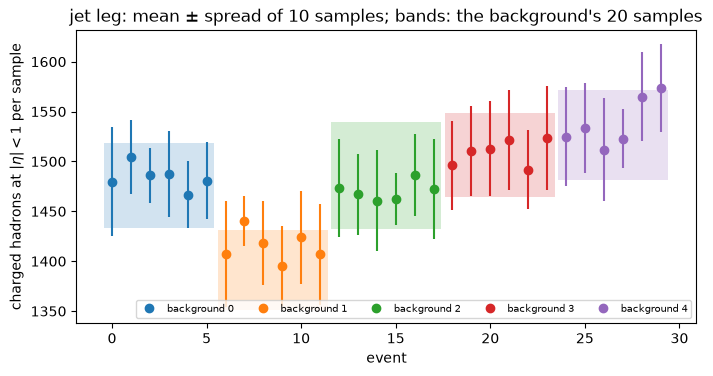

In [16]:
import matplotlib.pyplot as plt

d = mult["bulk_jet"]
bg_of = table.set_index("event")["bg_unit"]
per_event = d.groupby("event")["charged |eta|<1"].agg(["mean", "std"])
per_bg = mult["bulk_bg"].groupby("unit")["charged |eta|<1"].agg(["mean", "std"])

fig, ax = plt.subplots(figsize=(8, 3.8))
for b in per_bg.index:
    evs = per_event.index[bg_of[per_event.index] == b]
    m, s = per_bg.loc[b]
    ax.fill_between([evs.min() - 0.4, evs.max() + 0.4], m - s, m + s, color=f"C{b}", alpha=0.2, lw=0)
    ax.errorbar(evs, per_event.loc[evs, "mean"], per_event.loc[evs, "std"], fmt="o", color=f"C{b}",
                label=f"background {b}")
ax.set(xlabel="event", ylabel=r"charged hadrons at $|\eta|<1$ per sample",
       title="jet leg: mean $\\pm$ spread of 10 samples; bands: the background's 20 samples")
ax.legend(fontsize=7, ncol=5, loc="lower right")
within = d.groupby("event")["charged |eta|<1"].std().mean()
between = per_bg["mean"].std()
print(f"spread between the samples of one event: {within:.0f};  Poisson would give "
      f"{np.sqrt(d['charged |eta|<1'].mean()):.0f};  spread between the 5 backgrounds: {between:.0f}")

**What to notice.**

- **Events cluster by background.** The six events that share a background have about the
  same multiplicity as that background: the medium (its initial state and size) sets the
  number of hadrons, and a jet adds only a few.
- **The samples of one event spread by about ±43.** That is Cooper–Frye sampling of one
  fluid, somewhat wider than a Poisson distribution (±39); one reason is that a resonance
  decaying into two charged hadrons adds both at once.
- **The backgrounds differ by about as much** (±52 between the five), from fluctuations of
  the initial state within the 0–10 % class.
- So the 300 entries of `bulk_jet` are **not** 300 independent events: they are 30 events,
  from 5 media. Averages and errors must be taken per event (each event the mean over its
  samples), never per entry.

## 7. A cross-section-weighted spectrum with `hist`

Now the whole campaign: the $p_T$ spectrum of charged hadrons at $|\eta| < 1$, summed over
the three windows with their cross sections. Every event is the mean over its samples, so
an entry (one sample of event $e$ in window $k$) weighs

$$ w = \frac{\sigma_k}{N_k}\,\frac{1}{n_\text{samples}(e)}, $$

which makes the result $d\sigma/dp_T$ in mb/GeV. The weight is per entry; `ak.broadcast_arrays`
copies it to each of the entry's hadrons. We fill a [hist](https://hist.readthedocs.io)
histogram with `Weight` storage, which keeps the sum of squared weights for the errors:

In [17]:
import hist

EDGES = np.geomspace(0.2, 50, 25)                 # 24 log bins, as tutorial 10
N_SAMPLES = {"bulk_jet": "n_samples_jet", "bulk_bg": "n_samples_bg", "jet_frag": "n_samples_frag"}

def xsec_spectrum(set_name, tag, sigma=None):
    """dsigma/dpT [mb/GeV] of charged hadrons at |eta| < 1 of one hadron ntuple (bulk_jet or
    jet_frag: one unit per event), over all files of a set.  sigma: the cross section per
    window (default: the campaign's)."""
    win = camp[set_name]["windows"].arrays(["sigma_mb", "n_events"], library="np")
    per_event = (win["sigma_mb"] if sigma is None else sigma) / win["n_events"]   # sigma_k / N_k
    h = hist.Hist(hist.axis.Variable(EDGES, name="pt", label=r"$p_T$ [GeV]"),
                  storage=hist.storage.Weight())
    for path in sorted(folders[set_name].glob("*_hadrons.root")):
        with uproot.open(path) as rf:
            ev = rf["events"].arrays(["pthat_bin", N_SAMPLES[tag]], library="np")
            a = rf[tag].arrays(["event", "pid", "px", "py", "pz"])
        pt = np.hypot(a.px, a.py)
        eta = np.arcsinh(a.pz / pt)
        sel = charged(a.pid) & (np.abs(eta) < 1)
        w_entry = per_event[ev["pthat_bin"][a.event]] / ev[N_SAMPLES[tag]][a.event]
        w = ak.broadcast_arrays(w_entry, pt)[0]               # the entry's weight, per hadron
        h.fill(pt=ak.flatten(pt[sel]), weight=ak.flatten(w[sel]))
    return h

width = np.diff(EDGES)
aa_frag = xsec_spectrum(SET, "jet_frag")
aa_full = xsec_spectrum(SET, "bulk_jet") + aa_frag            # the whole jet event
pp_frag = xsec_spectrum(PP, "jet_frag")
sigma_pp = camp[PP]["windows"].arrays(["sigma_mb"], library="np")["sigma_mb"]
aa_frag_ppsigma = xsec_spectrum(SET, "jet_frag", sigma=sigma_pp)   # for the ratio
for name, h in [("Au+Au jet event", aa_full), ("Au+Au jet fragments", aa_frag), ("p+p jet fragments", pp_frag)]:
    print(f"{name:20s} sigma x <N_ch(|eta|<1, pT > 0.2 GeV)> = {h.sum().value:.4g} mb")
bulk = aa_full.values() - aa_frag.values()
print(f"the jet fragments outnumber the bulk above pT = {EDGES[np.argmax(aa_frag.values() > bulk)]:.1f} GeV")
for lo, hi in [(0.2, 2), (2, 5), (5, 50)]:
    b = (EDGES[:-1] >= lo) & (EDGES[1:] <= hi * 1.001)
    print(f"Au+Au / p+p jet fragments at {lo}-{hi} GeV: "
          f"{aa_frag_ppsigma.values()[b].sum() / pp_frag.values()[b].sum():.2f}")

Au+Au jet event      sigma x <N_ch(|eta|<1, pT > 0.2 GeV)> = 3.584 mb
Au+Au jet fragments  sigma x <N_ch(|eta|<1, pT > 0.2 GeV)> = 0.01132 mb
p+p jet fragments    sigma x <N_ch(|eta|<1, pT > 0.2 GeV)> = 0.0241 mb
the jet fragments outnumber the bulk above pT = 4.0 GeV
Au+Au / p+p jet fragments at 0.2-2 GeV: 0.41
Au+Au / p+p jet fragments at 2-5 GeV: 0.26
Au+Au / p+p jet fragments at 5-50 GeV: 0.18


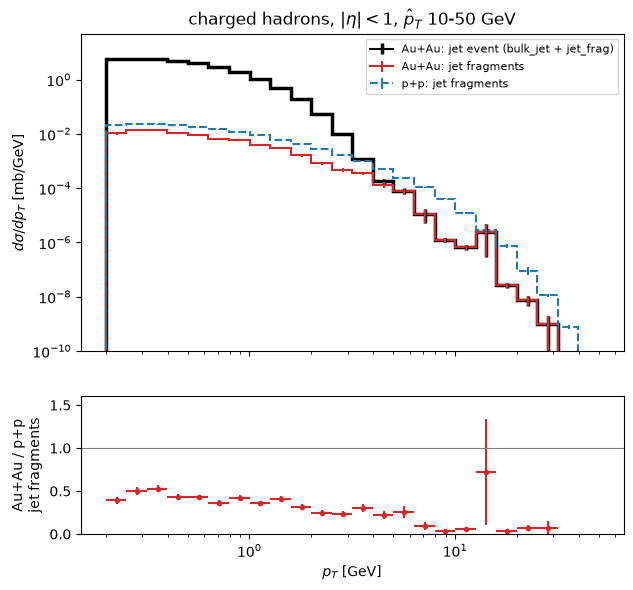

In [18]:
import mplhep as mh

fig, (ax, rx) = plt.subplots(2, 1, figsize=(7, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
mh.histplot(aa_full / width, ax=ax, label="Au+Au: jet event (bulk_jet + jet_frag)", flow="none", color="k", lw=2.5)
mh.histplot(aa_frag / width, ax=ax, label="Au+Au: jet fragments", flow="none", color="C3")
mh.histplot(pp_frag / width, ax=ax, label="p+p: jet fragments", flow="none", color="C0", ls="--")
ax.set(xscale="log", yscale="log", ylim=(1e-10, 50), ylabel=r"$d\sigma/dp_T$ [mb/GeV]", xlabel="",
       title=r"charged hadrons, $|\eta|<1$, $\hat p_T$ 10-50 GeV")
ax.legend(fontsize=8)
a, p = aa_frag_ppsigma, pp_frag
ok = a.values() > 0                               # bins with Au+Au hadrons
ratio = np.where(ok, a.values() / p.values(), np.nan)
ratio_err = ratio * np.sqrt(a.variances() / np.where(ok, a.values(), 1) ** 2 + p.variances() / p.values() ** 2)
c = aa_frag.axes[0].centers
rx.errorbar(c, ratio, ratio_err, xerr=[c - EDGES[:-1], EDGES[1:] - c], fmt="o", ms=3, color="C3")
rx.axhline(1, color="0.5", lw=0.8)
rx.set(xscale="log", ylim=(0, 1.6), xlabel=r"$p_T$ [GeV]", ylabel="Au+Au / p+p\njet fragments");

**What to notice.**

- **The bulk dominates below 4 GeV,** by more than two orders of magnitude at low $p_T$.
  Above 4 GeV the jet event is the jet's own fragments: the fluid makes no hadrons that hard.
- **The jet's own hadrons are suppressed in Au+Au** at every $p_T$ (the ratio panel; both
  weighted with the p+p cross sections): to about 0.4 below 2 GeV, 0.26 at 2–5 GeV, and
  mostly below 0.1 above 7 GeV (one bin at 14 GeV has a large error). The hard partons lost
  energy on their way through the medium, so their fragments are softer. The soft part of
  each shower was handed to the fluid (the droplets of tutorial 06): those hadrons are now in
  the bulk, as the wake of tutorial 07, not in `jet_frag`.
- **The Au+Au fragments are lumpy** above 10 GeV: 40 events per window are few. The p+p
  reference, with 1,500 per window, is smooth.
- **Only jets of p̂T 10–50 GeV are in here.** Softer jets, which were not generated, would add
  hadrons at low $p_T$, and harder ones at high $p_T$. The ratio compares the hadrons of the
  same jets with and without the medium.

## 8. The same numbers from the HDF5 files

The ROOT files are a copy of the HDF5 files, and the weighting is the HDF5 reader's: each
event the mean over its samples, each window weighted with its cross section. So
`HadronFileReader` on the `jet_frag` HDF5 files must give the same spectrum, bin for bin,
and the same errors:

In [19]:
from jetscape.hadrons_h5 import HadronFileReader

mid_charged = lambda ev, info: ev.charged & (np.abs(ev.eta) < 1)

def h5_spectrum(set_name):
    """sum_k sigma_k <dN/dpT>_k with the HDF5 reader -> (values, errors) per bin."""
    r = HadronFileReader(str(folders[set_name] / "*_hadrons_jet_frag.h5"))
    val, var = np.zeros(len(EDGES) - 1), np.zeros(len(EDGES) - 1)
    for k in range(len(r.pthat_bins)):
        sigma, _ = r.pthat_bin_sigma(k)
        v, e = r.hist("jet_frag", "pt", EDGES, mask=mid_charged, events=r.pthat_bin_events(k))
        val, var = val + sigma * v, var + (sigma * e) ** 2
    return val, np.sqrt(var), r.n_events

for name, h, s in [("Au+Au", aa_frag, SET), ("p+p", pp_frag, PP)]:
    val, err, n = h5_spectrum(s)
    dv = np.max(np.abs(h.values() - val) / np.where(val > 0, val, 1))
    de = np.max(np.abs(np.sqrt(h.variances()) - err) / np.where(err > 0, err, 1))
    print(f"{name:6s} {n:5d} events: largest relative difference ROOT/uproot vs HDF5 reader: "
          f"values {dv:.1e}, errors {de:.1e}")
    np.testing.assert_allclose(h.values(), val, rtol=1e-10)
    np.testing.assert_allclose(np.sqrt(h.variances()), err, rtol=1e-10)

Au+Au    120 events: largest relative difference ROOT/uproot vs HDF5 reader: values 8.4e-15, errors 4.6e-15


p+p     4500 events: largest relative difference ROOT/uproot vs HDF5 reader: values 7.9e-13, errors 3.2e-13


**What to notice.** The two agree to rounding ($10^{-15}$ to $10^{-12}$): the same hadrons, the same
cross sections, the same per-event normalisation. The errors also agree: the sum of squared
weights is the compound-Poisson error per event that the reader computes. (For `bulk_bg`,
where one background is used by several events, the reader adds a background's weights
before squaring; a plain `fill` per event would not.)

## 9. RDataFrame, if you have PyROOT

With ROOT ≥ 6.34 and its Python bindings, RDataFrame reads the same RNTuples and fills the
histogram in C++, on several threads. The analysis environment here has no PyROOT, so the
code below is **not executed**; it is the same computation as `xsec_spectrum`, and tutorial 10
runs the C++ version of it and checks it against the reader.

```python
# needs PyROOT (ROOT >= 6.34 for RNTuple) -- not run in this notebook
import ROOT
ROOT.EnableImplicitMT(4)
folder = folders["auau_stats"]
weight_mb = ROOT.RDataFrame("windows", str(folder / "stats_campaign.root")).AsNumpy(["weight_mb"])["weight_mb"]
model = ROOT.RDF.TH1DModel("h", ";p_{T} [GeV];d#sigma/dp_{T} [mb/GeV]", len(EDGES) - 1, EDGES)
total = None
for path in sorted(folder.glob("*_hadrons.root")):
    ev = ROOT.RDataFrame("events", str(path)).AsNumpy(["pthat_bin", "n_samples_frag"])
    w = weight_mb[ev["pthat_bin"]] / ev["n_samples_frag"]         # per event of this file
    table = "ROOT::RVecD{" + ",".join(f"{x:.17g}" for x in w) + "}"
    h = (ROOT.RDataFrame("jet_frag", str(path))
         .Define("pt", "sqrt(px * px + py * py)")
         .Define("eta", "asinh(pz / pt)")
         .Define("ch", "abs(pid) == 211 || abs(pid) == 321 || abs(pid) == 2212 || abs(pid) == 3222"
                       " || abs(pid) == 3112 || abs(pid) == 3312 || abs(pid) == 3334"
                       " || abs(pid) == 11 || abs(pid) == 13")
         .Define("pt_sel", "pt[ch && abs(eta) < 1]")
         .Define("w", f"{table}[event]")                             # the entry's weight
         .Histo1D(model, "pt_sel", "w"))
    if total is None:
        total = h.GetValue().Clone("h_frag")
    else:
        total.Add(h.GetPtr())
total.Scale(1.0, "width")                                            # dsigma/dpT [mb/GeV]
```

- `RDataFrame("jet_frag", file)` opens a TTree or an RNTuple alike.
- Per file, the weights come from that file's `events` table: `event` is the event number
  *inside* the file.
- `Histo1D` with a collection (`pt_sel`) and one weight per entry fills every element with
  that weight.
- The C++ version (with a lambda instead of the string) is `rdf_spectrum.C` in tutorial 10.

### Check your result

In [20]:
exp = json.load(open("expected/09_root_from_python.json"))
assert [f[t].num_entries for t in ["bulk_jet", "bulk_bg", "jet_frag"]] == exp["entries"]
np.testing.assert_allclose(cw["sigma_mb"], exp["sigma_auau_mb"], rtol=1e-6)
np.testing.assert_allclose(pw["sigma_mb"], exp["sigma_pp_mb"], rtol=1e-6)
np.testing.assert_allclose(mult["bulk_jet"]["charged |eta|<1"].mean(), exp["mean_nch_mid_bulk_jet"], rtol=1e-6)
np.testing.assert_allclose(aa_frag.values(), exp["dsigma_aa_frag"], rtol=1e-6)
np.testing.assert_allclose(pp_frag.values(), exp["dsigma_pp_frag"], rtol=1e-6)
np.testing.assert_allclose(aa_full.sum().value, exp["sigma_nch_aa_full"], rtol=1e-6)
print("All checks pass.")

All checks pass.


## Exercises

1. **Streamed.** Run `xsec_spectrum` for `pp_ref` on the streamed files instead of the
   downloaded ones (replace the folder's paths by `te.data(PP, name, stream=True)`). How long
   does it take, and how many bytes does it read? Which columns could you leave out?
2. **The background, and the wake.** Fill the spectrum of `bulk_bg`. Its entries belong to a
   background, used by 6 events: give each entry the sum of the weights of the events that
   use it (`events.bg_unit`), divided by `n_samples_bg`. Then look at `bulk_jet` − `bulk_bg`:
   is the difference positive? Why are its errors large here (compare tutorial 07)?
3. **One window at a time.** Plot $dN/dp_T$ per event of the jet fragments for each window
   separately (no cross sections). How does the highest hadron $p_T$ change with p̂T? Which
   window dominates the weighted spectrum at 10 GeV?
4. **The initiators.** From the jagged `ini_*` columns, histogram the leading initiator's
   $p_T$ divided by `pthat`, for Au+Au and for p+p. Are they the same distribution?

## Next steps

- The same files in C++: ROOT macros, `HadronFileReader.h`, RDataFrame and FastJet, in tutorial 10.
- The converter, the layout and the reader in C++: [ROOT and C++](https://jhputschke.github.io/js-contrib/analysis/root/).
- Normalisation, oversamples and cross-section weights: [Hadrons](https://jhputschke.github.io/js-contrib/analysis/hadrons/).
- Every dataset and attribute of the HDF5 files: [What a production writes](https://jhputschke.github.io/js-contrib/analysis/files/).